<a href="https://colab.research.google.com/github/aer00file/Eden_INFO4670_Fall2026/blob/main/Eden%20Johanson%20Assignment%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (11569 transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt


## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


CSV_PATH = "bread_basket.csv"  # update if needed
bread = pd.read_csv(CSV_PATH)

## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [11]:
bread.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   transaction      20507 non-null  int64 
 1   item             20507 non-null  object
 2   date_time        20507 non-null  object
 3   time             20507 non-null  object
 4   period_day       20507 non-null  object
 5   weekday_weekend  20507 non-null  object
dtypes: int64(1), object(5)
memory usage: 961.4+ KB


### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [12]:
bread.describe(include='all')

,transaction,item,date_time,time,period_day,weekday_weekend
count,20507.000000,20507,20507,20507,20507,20507
unique,NaN,94,159,1255,4,2
top,NaN,Coffee,2017-02-04,11:06,afternoon,weekday
freq,NaN,5471,292,52,11569,12807
mean,4976.202370,NaN,NaN,NaN,NaN,NaN
std,2796.203001,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN
25%,2552.000000,NaN,NaN,NaN,NaN,NaN
50%,5137.000000,NaN,NaN,NaN,NaN,NaN
75%,7357.000000,NaN,NaN,NaN,NaN,NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

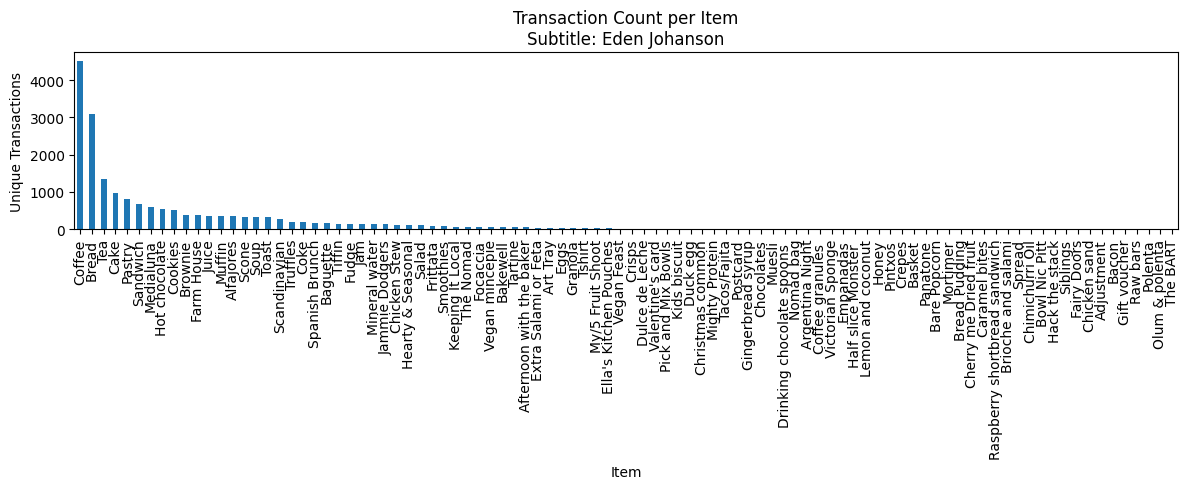

In [20]:
# c) Bar plot of transaction counts per item
subtitle = "Eden Johanson"
item_counts = bread.groupby('item')['transaction'].nunique().sort_values(ascending=False)

ax = item_counts.plot(kind='bar', figsize=(12,5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item"); plt.ylabel("Unique Transactions")
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [26]:
print("Coffee:", bread['item'].value_counts().get('Coffee', 0))
print("Tea:",bread['item'].value_counts().get('Tea', 0))
print("Alfajores:",bread['item'].value_counts().get('Alfajores', 0))
print("Juice:",bread['item'].value_counts().get('Juice', 0))
print("Chicken Stew:",bread['item'].value_counts().get('Chicken Stew', 0))


Coffee: 5471
Tea: 1435
Alfajores: 369
Juice: 369
Chicken Stew: 123


## 3) Frequent Itemset Mining with FP‑Growth (min_support = 0.02) (20 pts)
We pivot the data to a **transaction × item** one‑hot table (boolean), then run FP‑Growth.

In [41]:
te = TransactionEncoder()
te_ary = te.fit(bread).transform(bread)
oht = pd.DataFrame(te_ary, columns=te.columns_).astype(bool)
oht.head()

,_,a,c,d,e,i,k,m,n,o,p,r,s,t,w,y
0,False,True,True,False,False,True,False,False,True,True,False,True,True,True,False,False
1,False,False,False,False,True,True,False,True,False,False,False,False,False,True,False,False
2,True,True,False,True,True,True,False,True,False,False,False,False,False,True,False,False
3,False,False,False,False,True,True,False,True,False,False,False,False,False,True,False,False
4,True,True,False,True,True,True,False,False,False,True,True,True,False,False,False,True


## 4) Association Rules + Report Table (30 pts)
(metric = confidence, min_threshold = ?) Please find a suitable min_threshold

In [61]:
minsup = 0.01   # 5%
minconf = 0.3   # 30%

freq_b = fpgrowth(oht_b, min_support=minsup, use_colnames=True)
rules_b = association_rules(freq_b, metric='confidence', min_threshold=minconf)
rules_b[['antecedents','consequents','support','confidence','lift']].sort_values(['lift','confidence'], ascending=False).head(50)


,antecedents,consequents,support,confidence,lift
19,(Mineral water),(Hearty & Seasonal),0.015,0.500000,9.090909
18,(Tartine),"(Coffee, Tea)",0.015,0.500000,7.692308
2,(Hot chocolate),(Cookies),0.010,0.400000,6.666667
29,(Frittata),(Hearty & Seasonal),0.010,0.333333,6.060606
35,(Soup),(Hearty & Seasonal),0.015,0.333333,6.060606
33,(Frittata),"(Coffee, Tea)",0.010,0.333333,5.128205
26,(Victorian Sponge),(Tea),0.015,0.750000,3.947368
16,"(Tartine, Coffee)",(Tea),0.015,0.600000,3.157895
23,"(Coffee, Juice)",(Pastry),0.010,0.333333,2.898551
8,(Medialuna),(Pastry),0.020,0.307692,2.675585


## 5) Interpretation (10 pts)
**Interpret the rule `{Coffee, Cake} ⇒ {Bread}` in plain English.**

- **Support**: What fraction of *all* transactions contain Coffee, Cake, and Bread together?
- **Confidence**: Among baskets with Coffee and Cake, what share also include Bread?
- **Lift > 1** implies positive association; comment on practical meaning.

*Your notes:* (write your answer here)

>